In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.optimize import minimize_scalar

from network_creation.stats.topology_welfare import (
    er_centered_mean_welfare,
    max_er_centered_mean_welfare,
    reference_centered_mean_welfare,
)

%matplotlib inline
plt.style.use("science")
set_matplotlib_formats("svg")
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 17,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 13,
    "figure.titlesize": 19,
})

welfare_cmap = LinearSegmentedColormap.from_list(
    "welfare_blues", ("#eaf2f8", "#1f4e79")
)

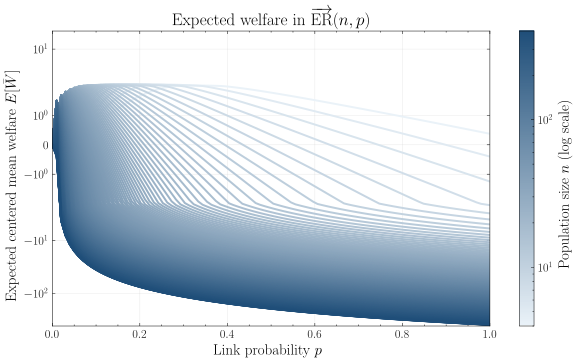

In [2]:
n_values = np.arange(4, 400, 1, dtype=int)
p_values = np.linspace(0, 1, 100, dtype=np.float64)

results = np.zeros((len(n_values), len(p_values)), dtype=np.float64)
for i, n in enumerate(n_values):
    for j, p in enumerate(p_values):
        results[i, j] = er_centered_mean_welfare(
            n_agents=n,
            benefit_to_cost_ratio=10 / (2 * n),
            directed_link_probability=p,
            distance_discount=0.9,
        )

figure, axis = plt.subplots(figsize=(8, 5), layout="compressed")

norm = LogNorm(vmin=n_values.min(), vmax=n_values.max())

for i, n in enumerate(n_values):
    axis.plot(
        p_values,
        results[i],
        color=welfare_cmap(norm(n)),
        linewidth=2,
    )

axis.set_title(r"Expected welfare in $\overrightarrow{\mathrm{ER}}(n,p)$")
axis.set_xlabel(r"Link probability $p$")
axis.set_ylabel(r"Expected centered mean welfare $E[\bar W]$")
axis.set_xlim(0, 1)
axis.set_yscale("symlog")
axis.grid(alpha=0.3)

scalar_mappable = plt.cm.ScalarMappable(cmap=welfare_cmap, norm=norm)
figure.colorbar(
    scalar_mappable,
    ax=axis,
    label=r"Population size $n$ (log scale)",
)

plt.show()

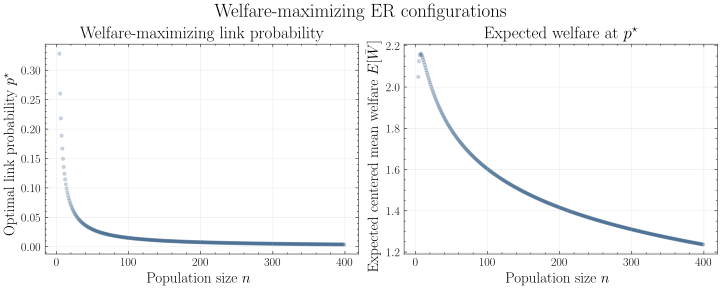

In [3]:
best_p_values = np.empty(len(n_values), dtype=np.float64)
best_welfare_values = np.empty(len(n_values), dtype=np.float64)
for i, n in enumerate(n_values):
    benefit_ratio = 5.0 / n
    optimum = minimize_scalar(
        lambda probability: -er_centered_mean_welfare(
            n_agents=int(n),
            benefit_to_cost_ratio=benefit_ratio,
            distance_discount=0.9,
            directed_link_probability=float(probability),
        ),
        bounds=(0.0, 1.0),
        method="bounded",
        options={"xatol": 1e-9, "maxiter": 500},
    )
    candidate_probabilities = (0.0, float(optimum.x), 1.0)
    candidate_welfare = [
        er_centered_mean_welfare(
            n_agents=int(n),
            benefit_to_cost_ratio=benefit_ratio,
            distance_discount=0.9,
            directed_link_probability=probability,
        )
        for probability in candidate_probabilities
    ]
    best_p_values[i] = candidate_probabilities[int(np.argmax(candidate_welfare))]
    best_welfare_values[i] = max_er_centered_mean_welfare(
        n_agents=int(n),
        benefit_to_cost_ratio=benefit_ratio,
        distance_discount=0.9,
    )

figure, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
    sharex=True,
    layout="compressed",
)

axes[0].scatter(
    n_values,
    best_p_values,
    color="#1f4e79",
    marker="o",
    s=10,
    alpha=0.2
)
axes[0].set_title("Welfare-maximizing link probability")
axes[0].set_xlabel(r"Population size $n$")
axes[0].set_ylabel(r"Optimal link probability $p^\star$")
axes[0].grid(alpha=0.3)

axes[1].scatter(
    n_values,
    best_welfare_values,
    color="#1f4e79",
    marker="o",
    s=10,
    alpha=0.2
)
axes[1].set_title(r"Expected welfare at $p^\star$")
axes[1].set_xlabel(r"Population size $n$")
axes[1].set_ylabel(r"Expected centered mean welfare $E[\bar W]$")
axes[1].grid(alpha=0.3)

figure.suptitle("Welfare-maximizing ER configurations")
plt.show()

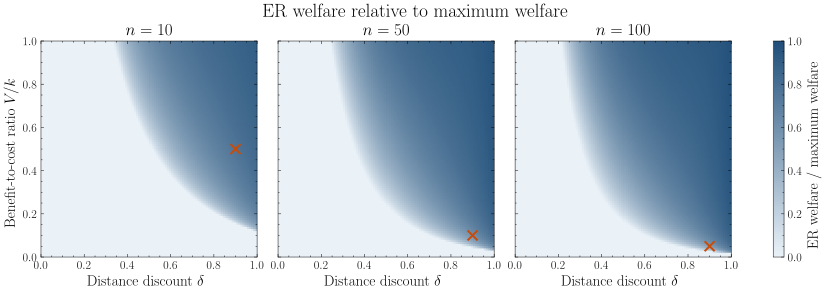

In [4]:
num = 100
population_sizes = (10, 50, 100)
benefit_to_cost_ratio_values = np.linspace(0.001, 0.999, num)
distance_discount_values = np.linspace(0.001, 0.999, num)
welfare_ratios = {}

for n in population_sizes:
    max_payoff = np.array(
        [
            [
                reference_centered_mean_welfare(
                    reference="max",
                    n_agents=n,
                    benefit_to_cost_ratio=v,
                    distance_discount=d,
                )
                for d in distance_discount_values
            ]
            for v in benefit_to_cost_ratio_values
        ],
        dtype=float,
    )
    er_payoff = np.array(
        [
            [
                reference_centered_mean_welfare(
                    reference="random",
                    n_agents=n,
                    benefit_to_cost_ratio=v,
                    distance_discount=d,
                )
                for d in distance_discount_values
            ]
            for v in benefit_to_cost_ratio_values
        ],
        dtype=float,
    )
    welfare_ratios[n] = er_payoff / (max_payoff + 1e-9)

figure, axes = plt.subplots(
    1,
    len(population_sizes),
    figsize=(12, 4),
    sharex=True,
    sharey=True,
    layout="compressed",
)

for axis, n in zip(axes, population_sizes):
    image = axis.imshow(
        welfare_ratios[n],
        origin="lower",
        aspect="equal",
        extent=(0.0, 1.0, 0.0, 1.0),
        cmap=welfare_cmap,
        vmin=0.0,
        vmax=1.0,
    )
    axis.set_title(rf"$n = {n}$")
    axis.set_xlabel(r"Distance discount $\delta$")
    axis.set_box_aspect(1)
    axis.plot(
        0.9,
        10 / (2 * n),
        marker="x",
        color="#c84c09",
        markersize=10,
        markeredgewidth=2,
    )

axes[0].set_ylabel(r"Benefit-to-cost ratio $V/k$")
figure.colorbar(
    image,
    ax=axes,
    label="ER welfare / maximum welfare",
)
figure.suptitle("ER welfare relative to maximum welfare")
plt.show()

In [5]:
distance_discount = 0.9
for N in [10, 50, 100]:
    benefit_to_cost_ratio = 10 / (2 * N)
    max_welfare_reference = reference_centered_mean_welfare(
        reference="max",
        n_agents=N,
        benefit_to_cost_ratio=benefit_to_cost_ratio,
        distance_discount=distance_discount,
    )
    er_welfare_reference = reference_centered_mean_welfare(
        reference="random",
        n_agents=N,
        benefit_to_cost_ratio=benefit_to_cost_ratio,
        distance_discount=distance_discount,
    )
    print(
        f"N={N}: Max Welfare = {max_welfare_reference:.4f}, ER Welfare = {er_welfare_reference:.4f}, Ratio = {er_welfare_reference / max_welfare_reference:.4f}"
    )

N=10: Max Welfare = 2.8260, ER Welfare = 2.1428, Ratio = 0.7582
N=50: Max Welfare = 3.0066, ER Welfare = 1.7915, Ratio = 0.5958
N=100: Max Welfare = 3.0284, ER Welfare = 1.6026, Ratio = 0.5292
